# 1 次のオールパスフィルタ(APF)

**どの周波数でも振幅は変えず、位相だけを変える**回路です。移相器(フェーズシフタ)とも呼びます。複数の信号の位相をそろえる、音に効果をつける(フェイザー)、などに使います。

この回では、正弦波で位相のずれを測る、ボード線図を測る、方形波を入れる、の 3 つを見ます。

## 回路

![1 次の APF の回路](04_apf/circuit.svg)

2 本の同じ抵抗 $R_1$ で作った反転増幅(ゲイン −1)と、R と C の LPF を通した非反転側の入力を組み合わせた回路です。単電源の回路では、C の下側を信号のグランド(2.5 V、Mimic の Vref)につなぎます。

## 原理

出力は「+ 入力の電圧の 2 倍 − 入力」になります(+ 入力には RC の LPF を通した電圧が入る)。LPF の出力を $L$ とすると $2L - V_\mathrm{in}$ で、

- 低い周波数:$L \approx V_\mathrm{in}$ → 出力 $\approx V_\mathrm{in}$(ゲイン +1、位相 0°)
- 高い周波数:$L \approx 0$ → 出力 $\approx -V_\mathrm{in}$(ゲイン −1、位相 −180°)

$$H(f) = \frac{1 - j\,f/f_c}{1 + j\,f/f_c}, \qquad f_c = \frac{1}{2\pi R C}$$

分子と分母の大きさがいつも等しいので、振幅は**どの周波数でも 1** です。位相は $-2\arctan(f/f_c)$ で、0° から −180° まで変わり、$f_c$ でちょうど −90° です。

| 周波数 | 振幅 | 位相 |
|---|---|---|
| $f \ll f_c$ | 1 | 0° |
| $f = f_c$ | 1 | −90° |
| $f \gg f_c$ | 1 | −180° に近づく |

![1 次の APF の周波数特性(模式図)](04_apf/response.svg)

## Mimic の設定と回路定数

| Mimic(Python) | ライブラリ(Arduino) | 回路 |
|---|---|---|
| `lab.mimic.filter1st_apf(fc)` | `mimic.setFilter1stAPF(fc)` | $f_c = \dfrac{1}{2\pi R C}$(位相が −90° になる周波数) |

例:$f_c$ = 100 Hz は、R = 16 kΩ、C = 0.1 µF にあたります。$R_1$ はゲインに関係しないので、同じ値(例 10 kΩ)の 2 本にします。

Mimic も、LPF の出力 $L$ から $2L - V_\mathrm{in}$ を計算しています。

## 準備:測定器につなぐ

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mimiclab import MimicLab, fit_sine, match_phase, plot_waveforms

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.0, mimic=20261123)

In [2]:
FC = 100  # frequency of the -90 degree phase shift [Hz]
lab.mimic.filter1st_apf(FC)

## 実験 1:正弦波を $f_c$ で入れる

振幅は変わらず、位相が 90° 遅れる(4 分の 1 周期ずれる)はずです。

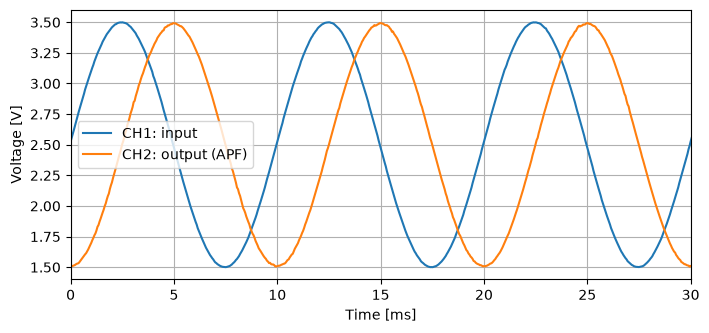

gain : 0.991   (theory 1)
phase: -91.2 deg (theory -90)


In [3]:
lab.fg.sine(FC, 1.0)
t, ch1, ch2 = lab.scope.capture(2000)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label="CH2: output (APF)")
ax.set_xlim(0, 30)
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

a1, p1, c1 = fit_sine(t, ch1, FC)
a2, p2, c2 = fit_sine(t, ch2, FC)
print(f"gain : {a2 / a1:.3f}   (theory 1)")
print(f"phase: {(p2 - p1 + 180) % 360 - 180:.1f} deg (theory -90)")

## 実験 2:ボード線図

[周波数特性を測る回](03_bode.ipynb)と同じ方法で測ります。ゲインは平ら、位相は 0° から −180° へ変わるはずです。

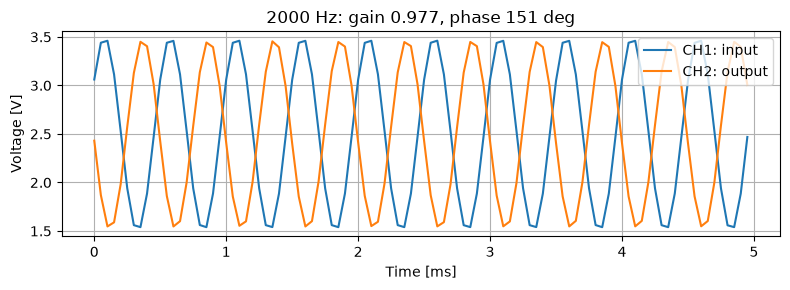

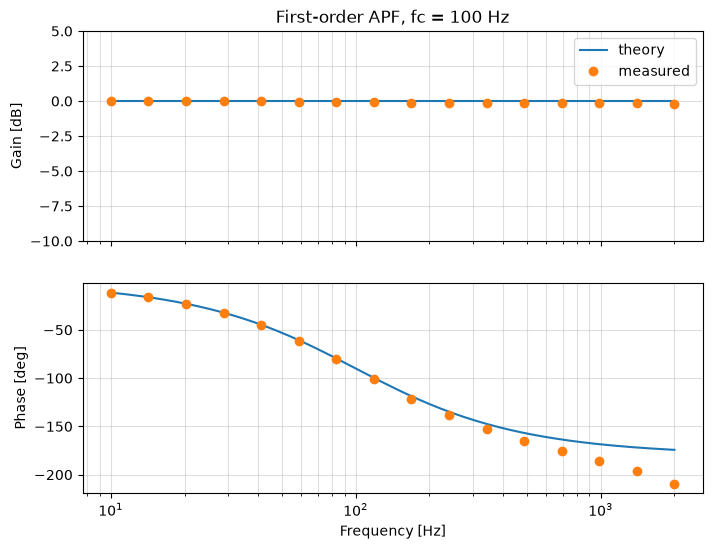

In [4]:
freqs = np.logspace(1, np.log10(2000), 16)   # 10 Hz - 2 kHz
apf = lab.frequency_response(freqs, monitor=True)

f_th = np.logspace(1, np.log10(2000), 200)
h = (1 - 1j * f_th / FC) / (1 + 1j * f_th / FC)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax1.semilogx(f_th, 20 * np.log10(abs(h)), "-", label="theory")
ax1.semilogx(apf.freq, apf.gain_db, "o", label="measured")
ax1.set_ylim(-10, 5)
ax1.set_ylabel("Gain [dB]")
ax2.semilogx(f_th, np.degrees(np.unwrap(np.angle(h))), "-", label="theory")
ax2.semilogx(apf.freq, match_phase(apf.phase, np.degrees(np.unwrap(np.angle((1 - 1j * apf.freq / FC) / (1 + 1j * apf.freq / FC))))), "o", label="measured")
ax2.set_ylabel("Phase [deg]")
ax2.set_xlabel("Frequency [Hz]")
for ax in (ax1, ax2):
    ax.grid(True, which="both", alpha=0.4)
ax1.set_title(f"First-order APF, fc = {FC} Hz")
ax1.legend()
plt.show()

各周波数で取り込んだ波形です(クリックで開きます)。


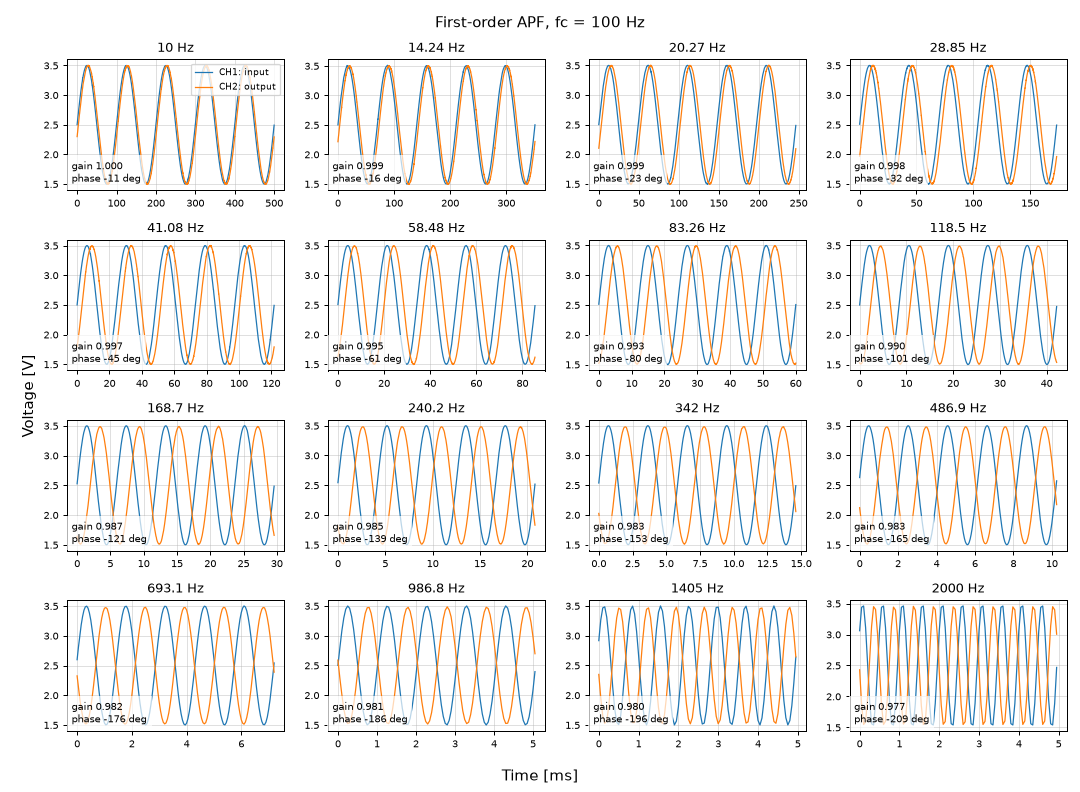

In [5]:
plot_waveforms(apf, title=f"First-order APF, fc = {FC} Hz", collapsed=True)

高い周波数では、位相が理論より少し多く遅れます。Mimic の遅れのためです([周波数特性を測る回](03_bode.ipynb)の実験 3)。

## 実験 3:方形波を入れる

方形波は、いろいろな周波数の正弦波の重ね合わせです。APF は周波数ごとに位相のずれ方が違うので、振幅は変えないのに波形の形が変わります。

入力が切り替わった瞬間は、高い周波数の成分だけが通るので、出力は**逆向き**に跳ねます(ゲイン −1)。そのあと、ゆっくり入力の値に追いつきます(低い周波数でゲイン +1)。跳ねる幅は入力の段差の 2 倍になるので、振幅を 0.5 V にして、電源の内側に収まるようにします。

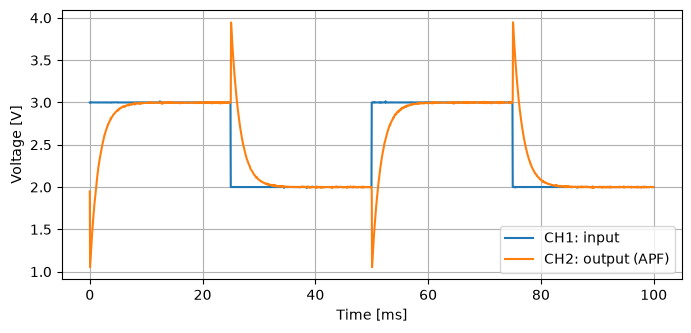

output: 1.052 - 3.948 V


In [6]:
lab.fg.square(20, 0.5)  # 20 Hz, 0.5 V peak
t, ch1, ch2 = lab.scope.capture(2000)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label="CH2: output (APF)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

print(f"output: {ch2.min():.3f} - {ch2.max():.3f} V")

## やってみよう

下のセルの値(大文字の名前)を**1 つずつ**変えて実行し、オシロの波形と数値がどう変わるかを自分の目で確かめましょう。どの値を順に試すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. $f_c$ を変えて、100 Hz の位相のずれを読む

100 Hz の正弦波を入れたまま $f_c$ を変えて、波形の位相のずれを見ます。
<details><summary>ヒント</summary>

`FC_TRY` を 30 → 100 → 300 と変えてみましょう。位相は $-2\arctan(100/f_c)$ で、30 Hz なら約 −147°、100 Hz なら −90°、300 Hz なら約 −37° です。振幅はどれも 1 倍のまま、波形が横にずれるだけです。

</details>

gain 0.991, phase -148.2 deg (theory -146.6)


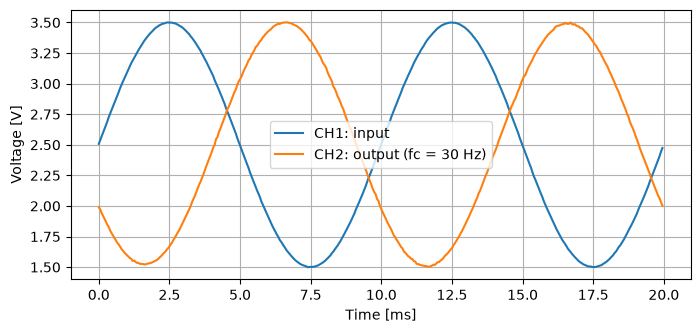

In [7]:
FC_TRY = 30   # [Hz]

lab.mimic.filter1st_apf(FC_TRY)
lab.fg.sine(100, 1.0)
t, ch1, ch2 = lab.scope.capture(400)
a1, p1, _ = fit_sine(t, ch1, 100)
a2, p2, _ = fit_sine(t, ch2, 100)
print(f"gain {a2 / a1:.3f}, phase {(p2 - p1 + 180) % 360 - 180:.1f} deg "
      f"(theory {-2 * np.degrees(np.arctan(100 / FC_TRY)):.1f})")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (fc = {FC_TRY} Hz)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

### 2. 方形波の振幅を大きくする
<details><summary>ヒント</summary>

`AMP` を 0.5 → 0.8 → 1.0 と上げてみましょう。切り替わりで、出力は入力の段差(2 × AMP)と同じだけ逆向きに跳ねます。もとの値(2.5 ± AMP)からさらに 2 × AMP 動くので、AMP = 0.8 あたりから電源の内側に収まらず、頭打ち(0.1 V や 4.9 V で平ら)になります。

</details>

output: 1.050 - 3.948 V


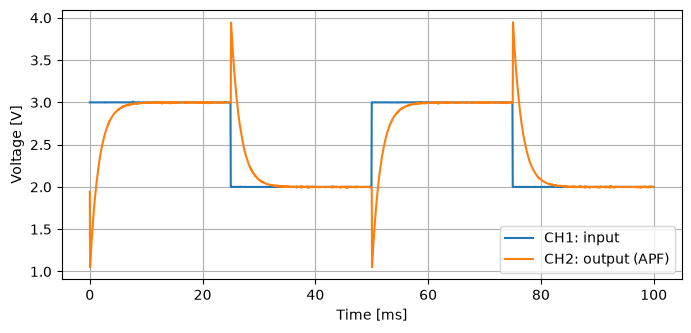

In [8]:
AMP = 0.5   # [V]

lab.mimic.filter1st_apf(FC)
lab.fg.square(20, AMP)
t, ch1, ch2 = lab.scope.capture(2000)
print(f"output: {ch2.min():.3f} - {ch2.max():.3f} V")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (APF)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

### 3. 三角波を入れる

100 Hz の三角波を APF に入れて、$f_c$ を変えます。振幅は変えないはずなのに、形はどうなるでしょうか。
<details><summary>ヒント</summary>

`FC_TRY` を 1000 → 100 → 30 と変えてみましょう。三角波も、いろいろな周波数(基本の周波数とその奇数倍)の正弦波の重ね合わせです。APF はどの成分の大きさも変えませんが、周波数ごとに位相のずれ方が違うので、重ね合わせた形が変わります。$f_c$ が信号よりずっと高いと、どの成分もほとんどずれず、形はそのままです。

</details>

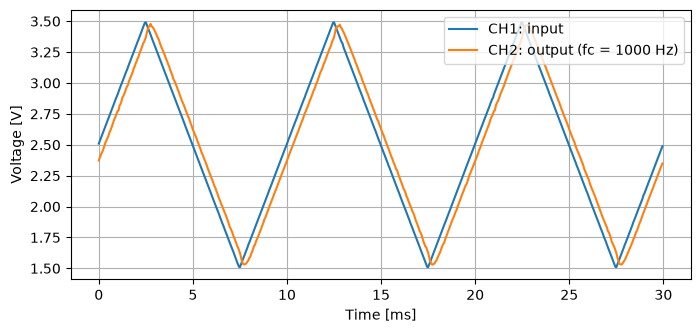

In [9]:
FC_TRY = 1000   # [Hz]

lab.mimic.filter1st_apf(FC_TRY)
lab.fg.triangle(100, 1.0)
t, ch1, ch2 = lab.scope.capture(600)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (fc = {FC_TRY} Hz)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

## まとめ

- 1 次の APF は、振幅を変えずに位相だけを 0° から −180° まで変える。$f_c = 1/(2\pi RC)$ で −90°。
- 回路は、LPF の出力 $L$ から $2L - V_\mathrm{in}$ を作る形になっている。
- 方形波を入れると、振幅は同じでも波形の形が変わる(切り替わりで逆向きに跳ねる)。

最後に Mimic を素通し(バイパス)に戻して、接続を閉じます。

In [10]:
lab.mimic.bypass()
lab.fg.sine(100, 1.0)
lab.close()